# Telco churn analysis

Which mobile customers are about to leave, and why? This notebook explores a **synthetic** customer base of a German mobile operator, trains two churn models, and checks whether the model recovers the *true* churn drivers that were used to generate the data.

> All data is synthetic. The churn drivers are known on purpose so the model's explanations can be verified, not just trusted.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
import pandas as pd
from churn_copilot.data import generate_customers, TRUE_EFFECTS
from churn_copilot import model as churn_model, viz
IMG = pathlib.Path.cwd().parent / 'docs' / 'images'
IMG.mkdir(parents=True, exist_ok=True)
import matplotlib.pyplot as plt
from IPython.display import Image, display
def show(fig, name):
    path = IMG / f'{name}.png'
    fig.savefig(path, dpi=130, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))
df = generate_customers(5000, seed=42)
print(f'{len(df):,} customers, churn rate {df.churned.mean():.1%}')
df.head()

5,000 customers, churn rate 25.2%


,customer_id,city,contract,plan,tenure_months,monthly_charge_eur,data_usage_gb,dropped_call_rate_pct,support_calls_90d,payment_method,family_bundle,age,churned
0,C-00001,Berlin,24-month,Basic 10GB,60,14.66,4.5,0.35,0,credit card,False,70,False
1,C-00002,Cologne,month-to-month,Plus 30GB,28,29.89,21.0,1.05,1,direct debit,False,55,False
2,C-00003,Hamburg,24-month,Unlimited 5G,24,45.04,28.6,0.48,0,credit card,False,22,False
3,C-00004,Cologne,12-month,Basic 10GB,2,16.06,5.1,1.48,1,direct debit,False,70,False
4,C-00005,Munich,month-to-month,Basic 10GB,13,13.97,1.2,0.49,1,direct debit,False,45,False


## 1. Where does churn come from?

Contract type is the biggest lever: month-to-month customers can leave with one month's notice.

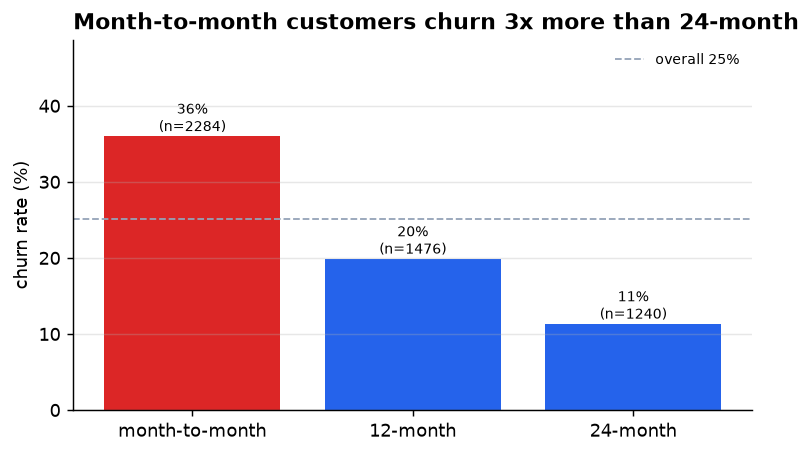

In [2]:
show(viz.churn_by(df, 'contract', 'Month-to-month customers churn 3x more than 24-month', order=['month-to-month', '12-month', '24-month']), 'churn_by_contract')

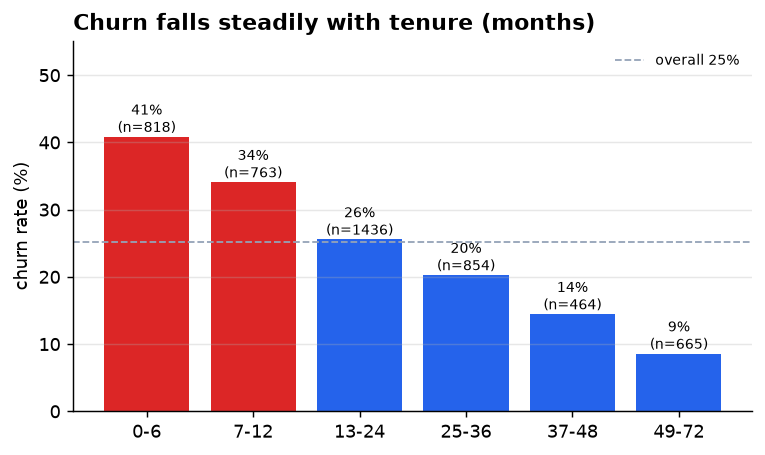

In [3]:
show(viz.churn_by_tenure(df), 'churn_by_tenure')

Network quality matters: customers with a dropped-call rate above 2% churn far more.

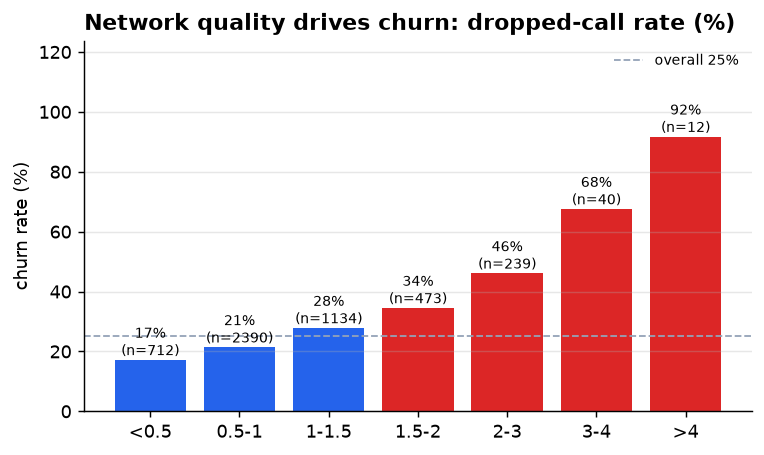

In [4]:
show(viz.dropped_calls_vs_churn(df), 'churn_by_dropped_calls')

Cologne looks like a problem city, but is it the *city* or the *network* there?

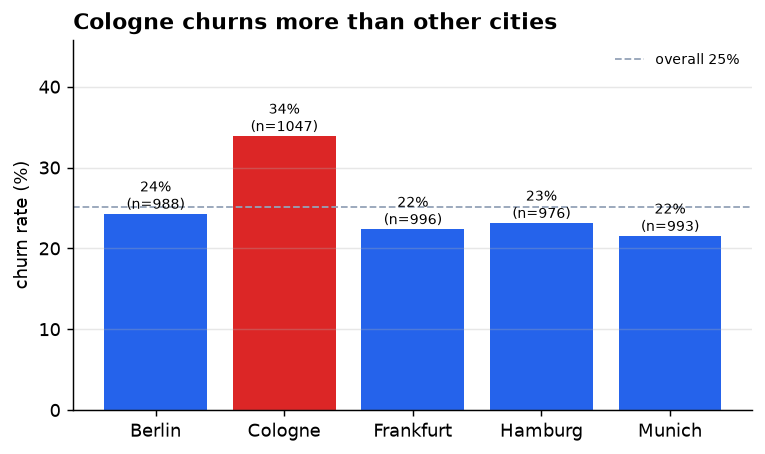

In [5]:
show(viz.churn_by(df, 'city', 'Cologne churns more than other cities'), 'churn_by_city')

In [6]:
df.groupby('city')[['dropped_call_rate_pct']].mean().round(2).T

city,Berlin,Cologne,Frankfurt,Hamburg,Munich
dropped_call_rate_pct,0.92,1.56,0.87,0.85,0.77


Cologne customers have roughly double the dropped-call rate. The model below shows that, once network quality is included, city itself adds almost nothing: the real cause is the network.

## 2. Models

Logistic regression (explainable) vs gradient boosting (challenger), on a 25% held-out test set.

In [7]:
m = churn_model.train(df)
pd.DataFrame({k: v for k, v in m.metrics.items() if isinstance(v, dict)}).T

,roc_auc,pr_auc,brier
logistic_regression,0.756,0.524,0.1572
gradient_boosting,0.716,0.487,0.1726


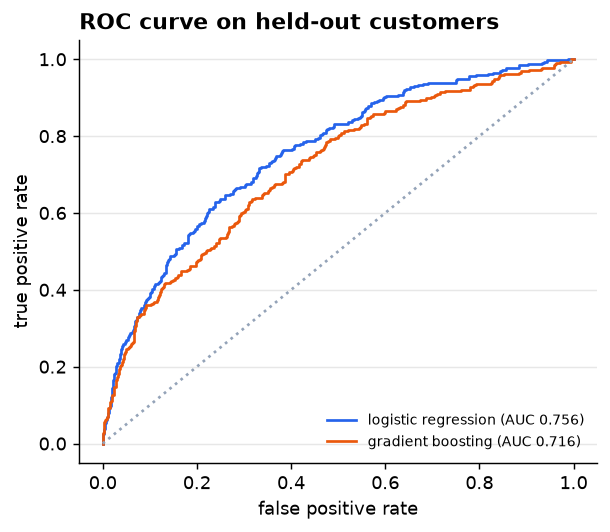

In [8]:
probs = {'logistic regression': m.logistic.predict_proba(m.X_test)[:, 1],
         'gradient boosting': m.boosting.predict_proba(m.X_test)[:, 1]}
show(viz.roc_curves(m.y_test, probs), 'roc_curves')

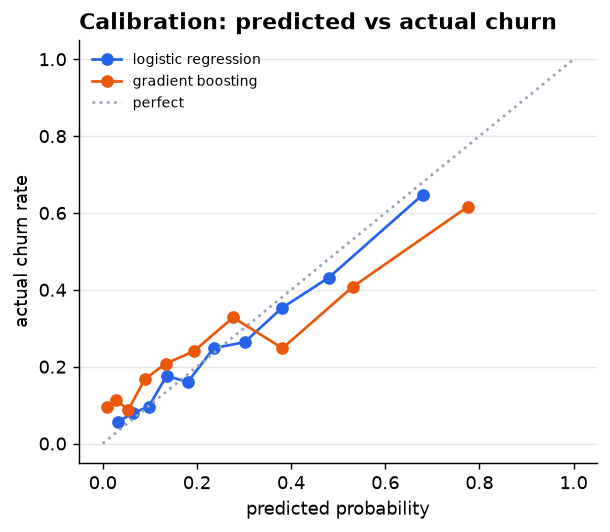

In [9]:
show(viz.calibration(m.y_test, probs), 'calibration')

The simpler model wins. The true churn process is close to logistic, so boosting has nothing extra to find and slightly overfits. Logistic regression is deployed: it is as accurate, better calibrated, and its per-customer explanations are exact.

## 3. Did the model learn the real drivers?

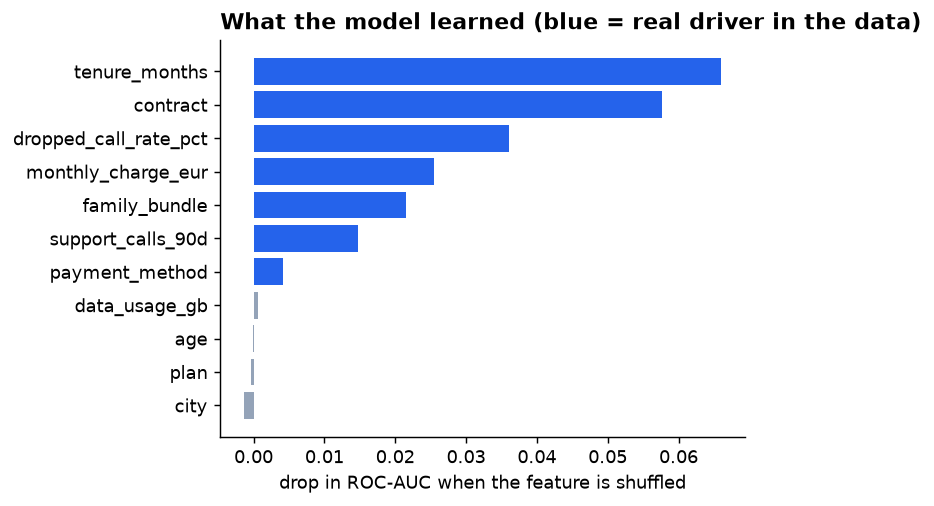

In [10]:
imp = churn_model.global_importance(m)
show(viz.importance_vs_truth(imp), 'importance_vs_truth')

In [11]:
pd.Series(TRUE_EFFECTS, name='true log-odds effect').to_frame()

,true log-odds effect
contract=month-to-month,1.400
contract=12-month,0.500
tenure_months (per month),-0.035
dropped_call_rate_pct (per pp above 0.8),0.700
support_calls_90d (per call),0.350
monthly_charge_eur (per € above 30),0.020
family_bundle,-0.800
payment=invoice,0.300


The top six learned features are exactly the six strongest true drivers. City, age and plan, which have no direct effect in the data, come out near zero. The model is picking up real signal, not artefacts.

## 4. Who should the retention team call?

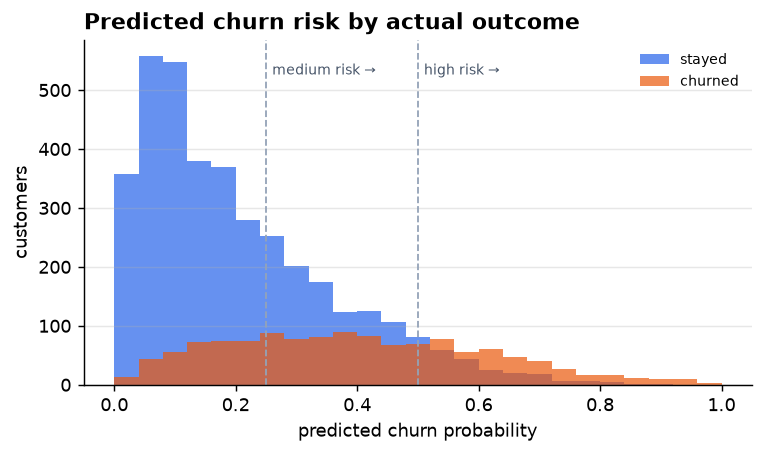

In [12]:
df['churn_probability'] = churn_model.score_all(m, df)
show(viz.risk_distribution(df), 'risk_distribution')

In [13]:
bands = pd.cut(df.churn_probability, [0, .25, .5, 1], labels=['low', 'medium', 'high'], include_lowest=True)
df.groupby(bands, observed=True).agg(customers=('customer_id', 'size'), actual_churn=('churned', 'mean')).round(3)

,customers,actual_churn
churn_probability,,
low,2910,0.121
medium,1448,0.344
high,642,0.634


In [14]:
import json
risky = df.loc[df.churn_probability.idxmax()]
print(json.dumps(churn_model.explain(m, risky), indent=1, ensure_ascii=False))

{
 "customer_id": "C-04124",
 "churn_probability": 0.997,
 "risk_band": "high",
 "top_risk_drivers": [
  {
   "feature": "dropped_call_rate_pct",
   "reason": "dropped-call rate of 5.91%",
   "log_odds": 3.22
  },
  {
   "feature": "support_calls_90d",
   "reason": "7 support calls in the last 90 days",
   "log_odds": 2.29
  },
  {
   "feature": "contract",
   "reason": "on a month-to-month contract",
   "log_odds": 0.98
  }
 ],
 "protective_factors": [
  {
   "feature": "monthly_charge_eur",
   "reason": "pays €17.18/month",
   "log_odds": -0.28
  },
  {
   "feature": "city",
   "reason": "lives in Cologne",
   "log_odds": -0.18
  }
 ]
}


These per-customer explanations feed the LLM copilot (`churn ask ...`), which combines them with the company's retention, contract, network-compensation and GDPR policies through RAG.